# RQ2延伸：区域专用模型与平均洋流条件模型

这份Notebook帮助我们回答两个问题：

1. **区域专用训练是否优于统一的全局训练？**
2. **把当地长期平均洋流作为已知变量，是否能改善预测？**

为了让比较公平，第一轮实验全部使用同一种算法——multi-output Ridge。这样模型表现的变化主要来自训练策略，而不是来自算法不同。

## 1. 实验逻辑

我们比较四种策略：

| 策略 | 训练方法 | 想回答的问题 |
|---|---|---|
| Global original | 原始98维输入，使用全部training cases | 原来的统一模型表现怎样？ |
| Regional | 四个regime分别训练一个模型 | 区域专用训练是否有效？ |
| Current-conditioned | 在98维输入后加入当地平均 $u,v$ 和速度大小 | 告诉模型当地平均洋流是否有帮助？ |
| Current-residual | 平均洋流先产生基础位移，Ridge只预测修正量 | 学习相对于平均洋流的偏差是否更容易？ |

所有超参数只在training partition内部，按drifter进行grouped 5-fold CV选择。Calibration partition不参与；test partition只在最后评价。

## 2. 准备环境并找到项目文件

这一步只加载Python包和确定路径，不会重新训练模型。

In [1]:
from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'RQ2' / '18_regime_conditioned_forecasting.py').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('请从data3001-project或其子文件夹打开本Notebook。')

SCRIPT_PATH = PROJECT_ROOT / 'RQ2' / '18_regime_conditioned_forecasting.py'
RESULT_DIR = PROJECT_ROOT / 'RQ2' / 'data' / 'rq2_extension'
FIGURE_DIR = PROJECT_ROOT / 'RQ2' / 'figures' / 'rq2_extension'

print('项目目录：', PROJECT_ROOT)
print('实验程序：', SCRIPT_PATH)
print('结果目录：', RESULT_DIR)

Matplotlib is building the font cache; this may take a moment.


项目目录： /Users/roger/Documents/data3001-project
实验程序： /Users/roger/Documents/data3001-project/RQ2/18_regime_conditioned_forecasting.py
结果目录： /Users/roger/Documents/data3001-project/RQ2/data/rq2_extension


## 3. 区域数据量

目前使用四个物理regime。训练模型时必须只使用相应区域的training cases；最终评价只使用相应区域的test cases。

同一个drifter可能在不同时刻经过不同regime，所以各行的drifter数量不能直接相加。

In [2]:
regime_summary = pd.read_csv(PROJECT_ROOT / 'RQ2' / 'data' / 'regime_summary.csv')
counts = (
    regime_summary[regime_summary['regime'].ne('Unclassified')]
    .pivot(index='regime', columns='partition', values=['n_cases', 'n_drifters'])
)
display(counts.astype(int))

n_cases                n_drifters              
partition      calibration test training calibration test training
regime                                                            
Kuroshio Core          120  139      646          42   45      208
Other Offshore         291  341     1599          32   41      167
Shelf                  200  112      525          31   28      132
Transition             158  165      816          42   43      216

## 4. 模型实际看到了什么？

原始模型的每个case有98个输入：

$$X_{original}=[\phi_0,\lambda_0,\text{过去24小时的东西/南北位移与速度}]$$

Current-conditioned模型额外获得forecast origin的长期平均洋流：

$$X_{conditioned}=[X_{original},\bar u,\bar v,\sqrt{\bar u^2+\bar v^2}]$$

其中 $\bar u$ 是平均东西向速度，$\bar v$ 是平均南北向速度。只提供速度大小是不够的，因为模型还需要知道方向。

In [3]:
regimes = pd.read_csv(PROJECT_ROOT / 'RQ2' / 'data' / 'forecast_case_regimes.csv')
display(regimes[[
    'forecast_case_id', 'partition', 'origin_longitude', 'origin_latitude',
    'u_clim', 'v_clim', 'current_speed_clim', 'depth_m', 'regime'
]].head(8))

,forecast_case_id,partition,origin_longitude,origin_latitude,u_clim,v_clim,current_speed_clim,depth_m,regime
0,1,training,125.20684,26.84464,0.213871,0.141451,0.256416,141.0,Shelf
1,2,training,125.22838,27.51924,0.073110,0.032119,0.079854,102.0,Shelf
2,3,training,125.42004,27.77936,0.062635,0.044626,0.076907,108.0,Shelf
3,4,training,125.22723,27.77967,0.061622,0.032389,0.069616,103.0,Shelf
4,5,training,125.40251,27.16178,0.147732,0.149418,0.210120,127.0,Shelf
5,6,training,125.17994,26.11981,0.532364,0.445907,0.694438,1698.0,Kuroshio Core
6,7,training,125.86490,26.22456,0.259265,0.308444,0.402935,2111.0,Transition
7,8,training,125.82167,27.16143,0.385134,0.531345,0.656244,205.0,Kuroshio Core


## 5. Residual模型是什么意思？

先根据forecast origin的长期平均流速产生基础位移：

$$Y_{clim}(t)=(3.6\,t\bar u,\;3.6\,t\bar v),$$

其中速度单位是m/s，乘以3.6后转换为km/h。然后模型学习：

$$R=Y_{true}-Y_{clim}.$$

最终预测为：

$$\widehat Y=Y_{clim}+\widehat R.$$

当前版本为了检验最简单的想法，将origin处的平均流速保持72小时不变。它还不是逐步查询空间流场的完整advection模型。

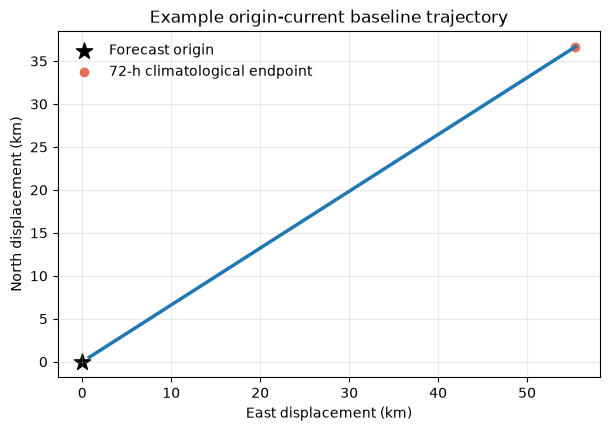

In [4]:
example = regimes.iloc[0]
hours = np.arange(1, 73)
east_km = example['u_clim'] * 3.6 * hours
north_km = example['v_clim'] * 3.6 * hours

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(east_km, north_km, linewidth=2.5)
ax.scatter([0], [0], marker='*', s=150, color='black', label='Forecast origin')
ax.scatter([east_km[-1]], [north_km[-1]], color='#E76F51', label='72-h climatological endpoint')
ax.set(xlabel='East displacement (km)', ylabel='North displacement (km)',
       title='Example origin-current baseline trajectory')
ax.grid(alpha=0.25); ax.legend(frameon=False); plt.show()

## 6. 超参数怎样选择？

每种策略都尝试：

$$\alpha\in\{0.1,1,10,100,1000,10000\}.$$

对于每一个 $\alpha$：

1. 将training drifters分成5组；
2. 每次用4组拟合、1组验证；
3. 计算完整72小时轨迹RMSE；
4. 选择平均validation RMSE最低的 $\alpha$；
5. 使用全部相应training cases重新拟合。

这样test cases不会参与模型或超参数选择。

In [5]:
selected = pd.read_csv(RESULT_DIR / 'selected_models.csv')
display(selected)

,strategy,regime,selected_alpha,n_training_cases,n_training_drifters
0,Global original,All,100.0,3591,311
1,Current-conditioned,All,100.0,3591,311
2,Current-residual,All,100.0,3591,311
3,Regional,Shelf,100.0,525,132
4,Regional,Kuroshio Core,10.0,646,208
5,Regional,Transition,100.0,816,216
6,Regional,Other Offshore,100.0,1599,167


## 7. 主要结果：区域专用模型是否更好？

下面读取已经运行完成的固定test-set结果。正的改善百分比代表新策略的RMSE低于Global original。

In [6]:
summary = pd.read_csv(RESULT_DIR / 'strategy_summary_by_regime.csv')
result_table = summary[[
    'regime', 'strategy', 'n_cases', 'n_drifters',
    'rmse_72h_km', 'median_72h_error_km',
    'median_normalised_error', 'rmse_improvement_vs_global_pct'
]].copy()
display(result_table.round(3))

,regime,strategy,n_cases,n_drifters,rmse_72h_km,median_72h_error_km,median_normalised_error,rmse_improvement_vs_global_pct
0,Kuroshio Core,Current-conditioned,139,45,88.531,68.364,0.431,3.852
1,Kuroshio Core,Current-residual,139,45,89.069,68.124,0.439,3.267
2,Kuroshio Core,Global original,139,45,92.078,66.656,0.521,0.000
3,Kuroshio Core,Regional,139,45,86.258,66.046,0.434,6.321
4,Other Offshore,Current-conditioned,341,41,56.513,43.668,0.665,0.035
5,Other Offshore,Current-residual,341,41,56.524,44.172,0.668,0.016
6,Other Offshore,Global original,341,41,56.533,43.701,0.671,0.000
7,Other Offshore,Regional,341,41,54.356,40.854,0.632,3.850
8,Shelf,Current-conditioned,112,28,42.846,27.869,0.997,7.554
9,Shelf,Current-residual,112,28,43.269,27.881,0.998,6.642


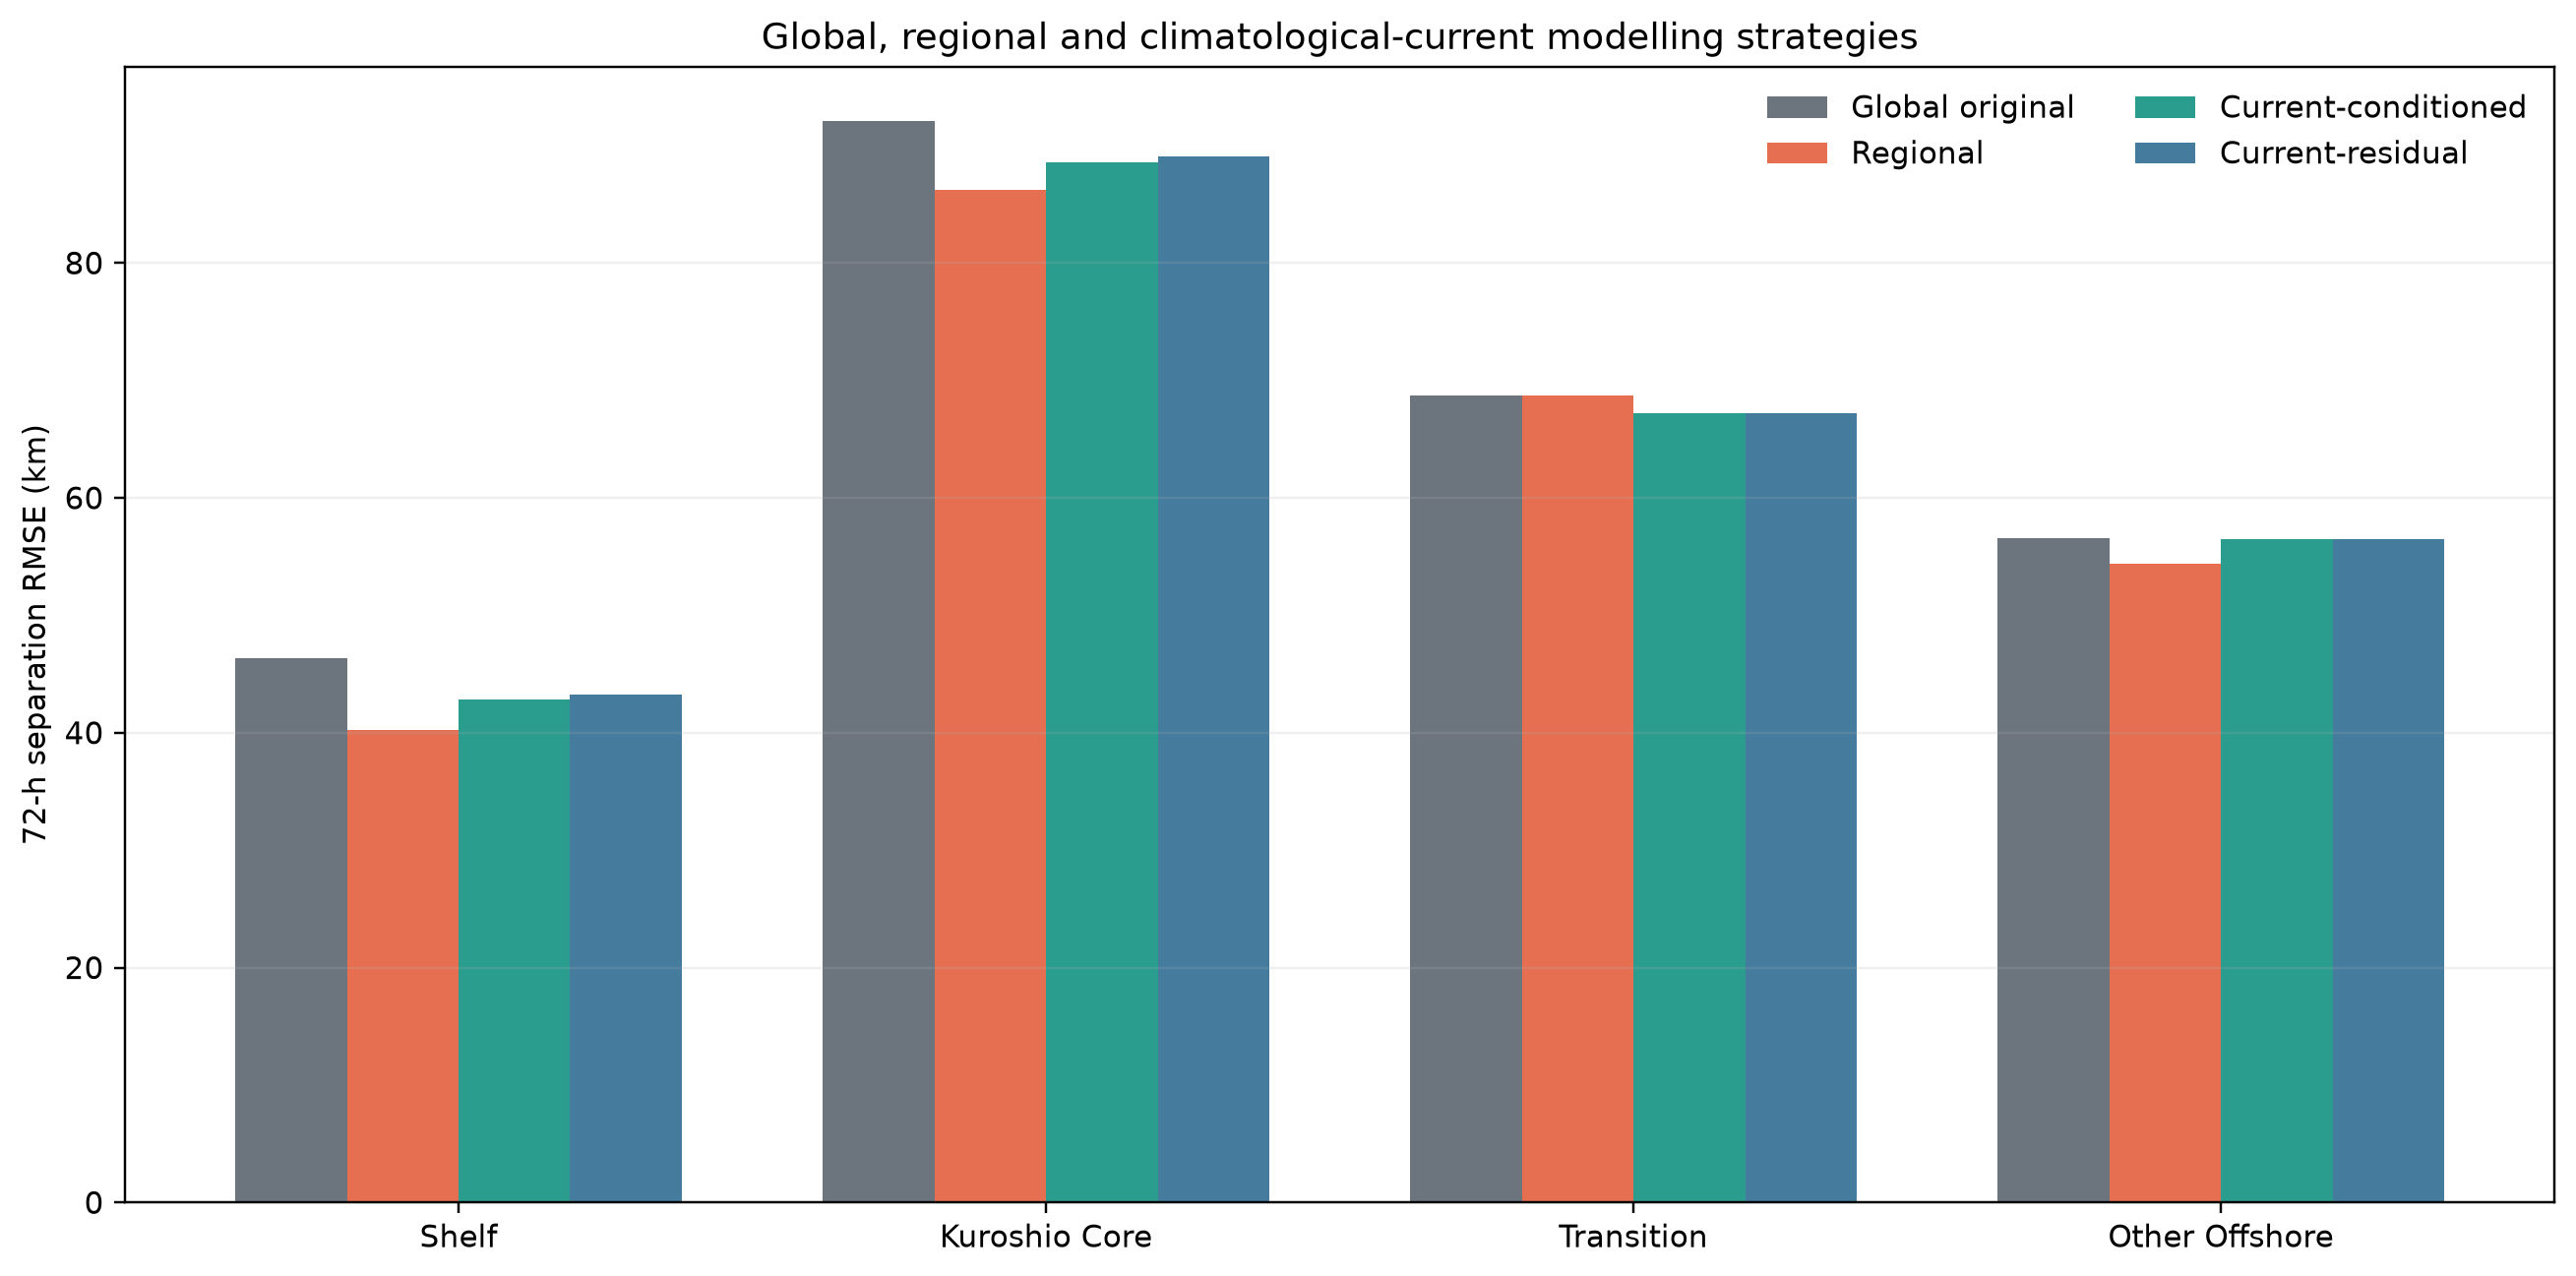

In [7]:
display(Image(filename=str(FIGURE_DIR / 'strategy_rmse_by_regime.png')))

### 怎样阅读上图？

- Shelf：Regional Ridge明显低于Global Ridge。
- Kuroshio Core：Regional Ridge也有所降低，但这里仍是绝对RMSE最大的区域。
- Transition：区域训练几乎没有改善。
- Other Offshore：Regional Ridge产生小幅改善。

因此不能简单地说‘区域模型一定更好’；其效果取决于该regime是否具有足够稳定、独特并且可以由现有样本学习的动力规律。

## 8. 改善是否可能只是抽样偶然？

同一个drifter的多个cases不是独立样本，因此不能把所有case当成彼此独立。代码以drifter为单位进行2,000次cluster bootstrap，并计算RMSE改善的95%区间。

如果区间跨过0，就不能确认新策略稳定优于Global original。

,regime,strategy,n_cases,n_drifters,rmse_improvement_vs_global_pct,ci_lower_pct,ci_upper_pct,ci_excludes_zero
0,Shelf,Regional,112,28,13.109,2.518,22.506,True
1,Shelf,Current-conditioned,112,28,7.554,0.888,12.588,True
2,Shelf,Current-residual,112,28,6.642,-2.423,12.750,False
3,Kuroshio Core,Regional,139,45,6.321,2.179,10.460,True
4,Kuroshio Core,Current-conditioned,139,45,3.852,-0.372,7.875,False
5,Kuroshio Core,Current-residual,139,45,3.267,-1.613,7.782,False
6,Transition,Regional,165,43,0.114,-2.628,2.980,False
7,Transition,Current-conditioned,165,43,2.258,-0.382,4.696,False
8,Transition,Current-residual,165,43,2.211,-0.773,5.137,False
9,Other Offshore,Regional,341,41,3.850,2.134,5.452,True


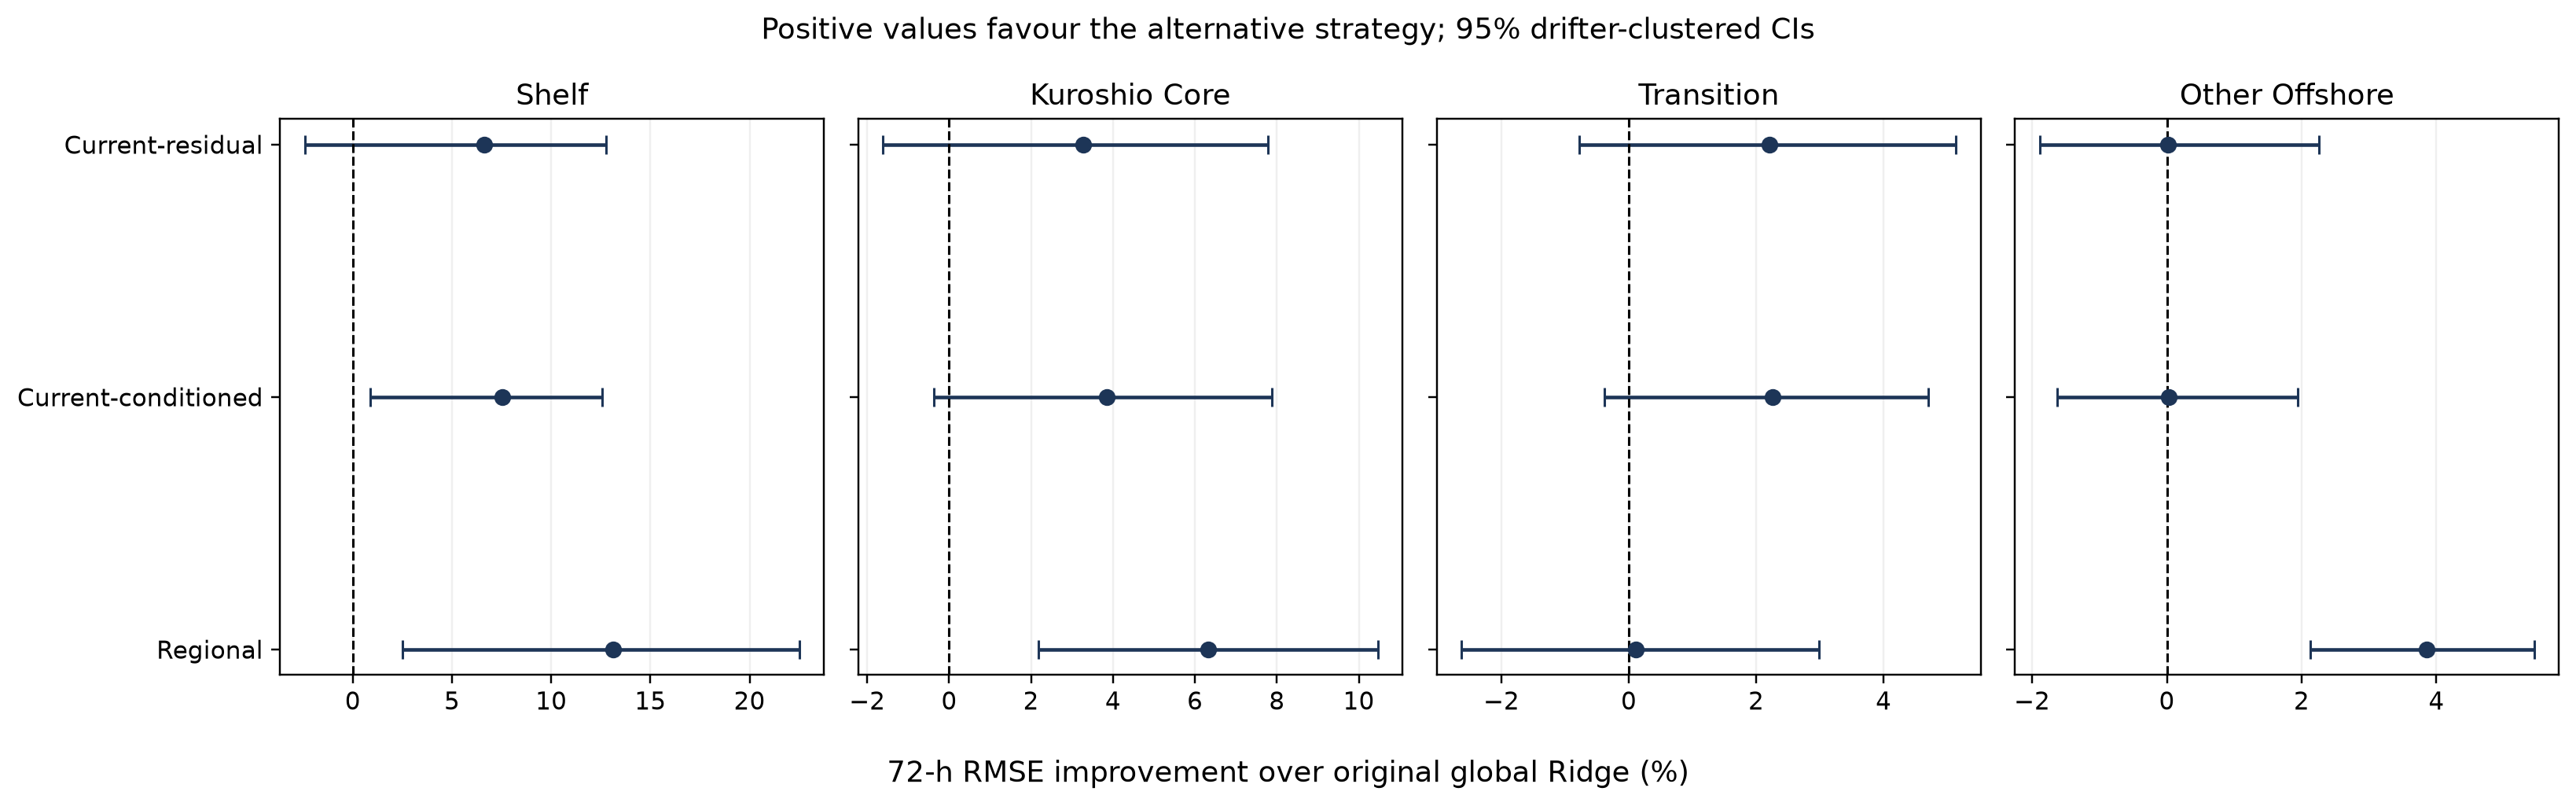

In [8]:
bootstrap = pd.read_csv(RESULT_DIR / 'strategy_cluster_bootstrap.csv')
display(bootstrap.round(3))
display(Image(filename=str(FIGURE_DIR / 'strategy_improvement_cluster_ci.png')))

## 9. 当前可以得出什么结论？

### 区域专用训练

- Shelf：RMSE改善约13.11%，95% CI为2.52%至22.51%。
- Kuroshio Core：改善约6.32%，95% CI为2.18%至10.46%。
- Other Offshore：改善约3.85%，95% CI为2.13%至5.45%。
- Transition：改善约0.11%，区间跨过0。

所以第一轮Ridge实验支持Shelf、Kuroshio Core和Other Offshore使用区域专用模型，但不支持Transition。

### 加入当地平均流速

- Current-conditioned在Shelf改善约7.55%，区间不包含0。
- Kuroshio Core点估计改善约3.85%，但区间略微跨过0。
- Transition和Other Offshore没有明确证据。
- 简单Current-residual模型没有得到更强的统计证据。

因此目前不能说‘平均流速已经被证明能改善所有区域’，只能说它在Shelf有明确帮助，在Kuroshio中存在需要继续检验的信号。

## 10. 可选：完整重新运行实验

默认保持 `RUN_FULL_EXPERIMENT=False`，因为前面的表格已经读取保存结果。若修改了数据或代码，再改为 `True`。完整实验包含多组5-fold CV和2,000次bootstrap，通常需要约两分钟。

In [9]:
RUN_FULL_EXPERIMENT = False

if RUN_FULL_EXPERIMENT:
    spec = importlib.util.spec_from_file_location('rq2_extension', SCRIPT_PATH)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    module.main()
else:
    print('没有重新训练；当前显示的是已经保存并验证过的结果。')

没有重新训练；当前显示的是已经保存并验证过的结果。


## 11. 下一步

1. 用Random Forest重复Global、Regional和Current-conditioned三种策略。
2. 将residual baseline升级为每小时在新预测位置查询当地平均流场，而不是固定origin流速。
3. 建立12个月度气候平均流场，加入季节信息。
4. 使用East China Sea训练、South Japan测试，再反向测试，以检验真正的跨区域泛化。
5. 同时报告绝对RMSE、normalized error和forecast skill。